# WP09 — Null politikası ve son eğitim kapısı v3

**Bu notebook model kurmaz/fit etmez, optimizer çalıştırmaz ve gerçek PT skoru üretmez.** Kabul edilen encoder ve bütün önceki sonuçlar korunur.700 önerisi topoloji/null fizibilitesidir; tahmin performansından seçilmedi. İncelenen soru: başarısız degree-preserving null nasıl açıklanır ve bütün modellerin karşılaştırılabilirliği nasıl korunur?

Tek v3 önerisi: aynı generator ve10E/max200E/%50 kuralı;önceden tanımlı3 null;ortak geçerli inner kesişimi;minimum2;başarısızlık NA. Üretim bütçesi/seed değiştirilmez. v3 training_enabled=False;ayrı onay beklenir.

In [1]:
from pathlib import Path
import json,re,numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').is_file():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
QA=ROOT/'reports/qa/WP09/null_gate_v3';FIG=ROOT/'reports/figures/WP09/null_gate_v3';FIG.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_rows',140);pd.set_option('display.max_columns',20);pd.set_option('display.max_colwidth',120)
d=json.loads((QA/'failure_diagnosis.json').read_text(encoding='utf-8'))
c=json.loads((ROOT/'configs/WP09_training_PROPOSED_v3.json').read_text(encoding='utf-8'))
done=json.loads((QA/'null_preflight_complete.json').read_text(encoding='utf-8'))
rows=pd.read_csv(QA/'null_preflight_700_three_replicates.csv',keep_default_na=False)
scope=pd.read_csv(QA/'common_inner_outer_preflight.csv',keep_default_na=False)
display(pd.DataFrame([{'primary_eşik_önerisi':700,'onaylı_eşik':c['threshold']['approved_primary'],
    'null_adayı':len(rows),'tekrar':3,'korunan_dosya':done['prior_files_verified'],
    'eski40_r0_aynı':done['old_replicate_zero_40_exactly_reproduced'],'eğitim':c['training_enabled']}]))
display(pd.DataFrame([d]).T.rename(columns={0:'kanıt'}))

,primary_eşik_önerisi,onaylı_eşik,null_adayı,tekrar,korunan_dosya,eski40_r0_aynı,eğitim
0,700,None,120,3,1567,True,False


,kanıt
context,stress_o02_i02
seed,20274406
nodes_all,84
active_degree_nodes,29
edges,105
minimum_removed_for_50pct,53
old_removed_original_edges,51
old_retained_original_edges,54
accepted_swap_target_met,True
attempt_budget_exhausted,False


**Yorum:** Eski40 R0 seed/status/endpoint hash'i aynıdır.84 proteinli bağlamın PPI kenarlarına29 düğüm katılır;105 kenarda%50 için en az53 kenar değişmelidir. Eski51/105 endpoint NA kalır. Protein sayısı veya seed değiştirilmedi. Derece korunması endpoint farkının monoton artacağı anlamına gelmez.

## 1. Swap sayısı, farklı kalan eski kenar sayısı değildir

,swaps_per_edge,attempts,accepted_swaps,shared_endpoint_rejections,existing_pair_rejections,removed_original_edges,changed_fraction,passes_change_rule
0,10,3801,1050,637,2114,51,0.485714,False
1,50,18905,5250,3190,10465,53,0.504762,True
2,100,38025,10500,6478,21047,56,0.533333,True


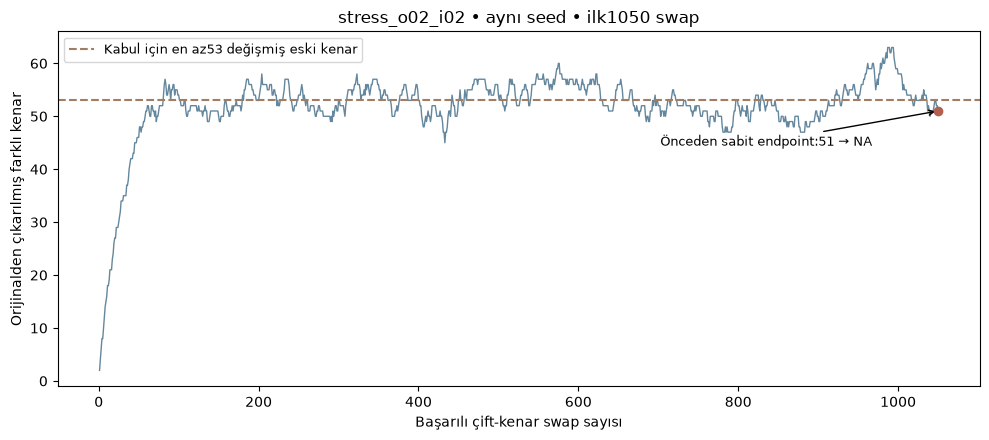

In [2]:
trace=pd.read_csv(QA/'failure_full_swap_trace.csv');first=trace[trace.accepted_swaps<=1050]
endpoints=pd.read_csv(QA/'failure_fixed_horizon_diagnostics.csv')
display(endpoints[['swaps_per_edge','attempts','accepted_swaps','shared_endpoint_rejections','existing_pair_rejections','removed_original_edges','changed_fraction','passes_change_rule']])
fig,ax=plt.subplots(figsize=(10,4.5));ax.plot(first.accepted_swaps,first.removed_original_edges,color='#64879d',lw=1)
ax.axhline(53,color='#a37d62',ls='--',label='Kabul için en az53 değişmiş eski kenar')
ax.scatter([1050],[51],color='#b25f50',zorder=4);ax.annotate('Önceden sabit endpoint:51 → NA',(1050,51),xytext=(-200,-25),textcoords='offset points',arrowprops=dict(arrowstyle='->'),fontsize=9)
ax.set(xlabel='Başarılı çift-kenar swap sayısı',ylabel='Orijinalden çıkarılmış farklı kenar',title='stress_o02_i02 • aynı seed • ilk1050 swap');ax.legend(fontsize=9)
plt.tight_layout();plt.savefig(FIG/'01_endpoint_trace.png',dpi=160);plt.show()

**Yorum:** 1050 swap3801 denemede tamamlandı;max21000 bütçe tükenmedi.637 ortak uç,2114 mevcut/duplicate yeni çift reddi var. Kümülatif822 orijinal çıkarma−771 geri ekleme=51 net değişim. Ara noktada63 değişmiş kenara ulaşılıp finalde51'e dönülmesi fiziksel/algoritmik “imkânsızlık” açıklamasını dışlar.50E/100E endpointleri bu yürüyüşte geçse de sadece tanısaldır;eski null'u değiştirmediler. İlk başarılı ara noktayı seçen yeni stop kuralı geriye dönük uygulanmadı. Daha uzun yürüyüş uniform mixing veya her zaman daha yüksek değişim garantisi değildir.

## 2. Aynı generator, üç önceden tanımlı tekrar

,replicate,aday,kabul,minimum_değişim,maksimum_değişim
0,0,40,39,0.485714,0.716867
1,1,40,39,0.466667,0.744444
2,2,40,39,0.495726,0.722222


,context,replicate,seed,changed_fraction,status,artifact_file
17,primary_o02_i01,2,22272306,0.495726,NA_shuffle_insufficient,
78,stress_o02_i02,0,20274406,0.485714,NA_shuffle_insufficient,
79,stress_o02_i02,1,21274406,0.466667,NA_shuffle_insufficient,


replicate,0,1,2
context,,,
primary_o01_final,OK_degree_preserving_null,OK_degree_preserving_null,OK_degree_preserving_null
primary_o01_i01,OK_degree_preserving_null,OK_degree_preserving_null,OK_degree_preserving_null
primary_o01_i02,OK_degree_preserving_null,OK_degree_preserving_null,OK_degree_preserving_null
primary_o01_i03,OK_degree_preserving_null,OK_degree_preserving_null,OK_degree_preserving_null
primary_o02_final,OK_degree_preserving_null,OK_degree_preserving_null,OK_degree_preserving_null
primary_o02_i01,OK_degree_preserving_null,OK_degree_preserving_null,NA_shuffle_insufficient
primary_o02_i02,OK_degree_preserving_null,OK_degree_preserving_null,OK_degree_preserving_null
primary_o02_i03,OK_degree_preserving_null,OK_degree_preserving_null,OK_degree_preserving_null
primary_o03_final,OK_degree_preserving_null,OK_degree_preserving_null,OK_degree_preserving_null


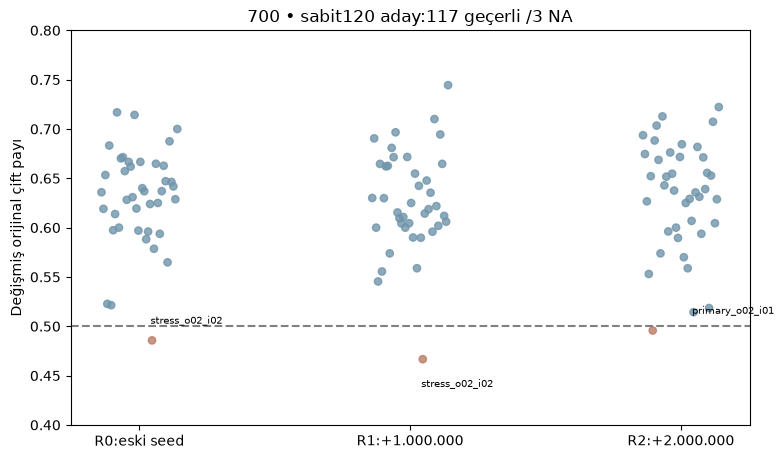

In [3]:
summary=rows.groupby('replicate').agg(aday=('context','count'),kabul=('status',lambda s:int(s.eq('OK_degree_preserving_null').sum())),
    minimum_değişim=('changed_fraction','min'),maksimum_değişim=('changed_fraction','max')).reset_index()
display(summary);display(rows[rows.status.ne('OK_degree_preserving_null')][['context','replicate','seed','changed_fraction','status','artifact_file']])
display(rows.pivot(index='context',columns='replicate',values='status'))
fig,ax=plt.subplots(figsize=(8,4.7))
for rep in range(3):
    sub=rows[rows.replicate.eq(rep)];offset=np.linspace(-.14,.14,len(sub))
    ax.scatter(rep+offset,sub.changed_fraction,c=np.where(sub.status.eq('OK_degree_preserving_null'),'#7095aa','#ba7c66'),s=28,alpha=.8)
    for failed in sub[sub.status.ne('OK_degree_preserving_null')].itertuples():
        ax.annotate(failed.context,(rep,failed.changed_fraction),xytext=(8,-20 if rep==1 else 12),textcoords='offset points',fontsize=7)
ax.axhline(.5,color='gray',ls='--');ax.set_xticks([0,1,2],['R0:eski seed','R1:+1.000.000','R2:+2.000.000'])
ax.set(ylim=(.4,.8),ylabel='Değişmiş orijinal çift payı',title='700 • sabit120 aday:117 geçerli /3 NA')
plt.tight_layout();plt.savefig(FIG/'02_three_null_replicates.png',dpi=160);plt.show()

**Yorum:** Tekrarlar en iyi seed'i seçmek için kullanılmaz. R0 her yerde eski adaydır;R1/R2 v2'de zaten yazılan seed formülünden gelir. Her tekrar gerçek grafla yeniden başlar. Aynı-degree/simple/aynı-node kısıtları,loop/duplicate reddi ve≥%50 endpoint testi tümünde aynıdır.3 NA iki inner contexttedir;geçerli diğer tekrarlar bunların yerine konmaz. Başarılı117 adaydan,eksik contextlerdeki3 başarılı aday da primary ortak kapsamdan çıkarılır:114 null kullanımlık plan,3 açık ek kapsam kaybı vardır.

## 3. Bütün modellerde ortak inner kapsam

,seçenek,etki,karar_ve_sınır
0,Yalnız başarısız deneyi NA; her varyant kendi inner foldlarını kullanır,"Real/noPPI üç, shuffled iki fold kullanabilir",Birincil kıyas için önerilmez: seçim/epoch bilgi kapsamı farklılaşır
1,Ortak inner kesişim + minimum3,Üçü de bütün inner foldları gerektirir,Bu preflightta primary outer2 ve stress outer2 ana kıyas NA olur; daha fazla kapsam kaybı
2,Ortak inner kesişim + minimum2,Bir null bile başarısızsa ilgili fold bütün varyantlarda dışlanır,"ÖNERİLEN:10 outer topolojik olarak hazır; iki outerda2,diğerlerinde3 inner; gelecekte metrik NA ayrı kontrol"
3,Gerçek/noPPI kenarıyla null doldurma,PPI yapısı yanlış etiketlenir,YASAK; ablation sorusu değişir
4,Başarılı seed/ilk başarılı ara nokta seçme,Sonradan seçilmiş koşullu grafik dağılımı,"Önerilmez; eski başarısızlık korunur, seed/stop kuralı değiştirilmez"
5,Herkese daha büyük sabit bütçeli yeni generator,Ayrı sürüm ve tüm-null QA gerektirir,Şimdilik gerekli değil: mevcut sabit üç tekrar+ortak minimum2 planı uygulanabilir; mixing/başarı garantisi vermez


,protocol,outer_fold,common_valid_inner_folds,common_valid_inner_count,outer_all_three_nulls_valid,topology_preflight_status,training_authorized,metric_evaluability_not_yet_tested
0,primary,1,"1,2,3",3,True,READY_FOR_FUTURE_INNER_EVALUATION,False,True
1,primary,2,"2,3",2,True,READY_FOR_FUTURE_INNER_EVALUATION,False,True
2,primary,3,"1,2,3",3,True,READY_FOR_FUTURE_INNER_EVALUATION,False,True
3,primary,4,"1,2,3",3,True,READY_FOR_FUTURE_INNER_EVALUATION,False,True
4,primary,5,"1,2,3",3,True,READY_FOR_FUTURE_INNER_EVALUATION,False,True
5,stress,1,"1,2,3",3,True,READY_FOR_FUTURE_INNER_EVALUATION,False,True
6,stress,2,"1,3",2,True,READY_FOR_FUTURE_INNER_EVALUATION,False,True
7,stress,3,"1,2,3",3,True,READY_FOR_FUTURE_INNER_EVALUATION,False,True
8,stress,4,"1,2,3",3,True,READY_FOR_FUTURE_INNER_EVALUATION,False,True
9,stress,5,"1,2,3",3,True,READY_FOR_FUTURE_INNER_EVALUATION,False,True


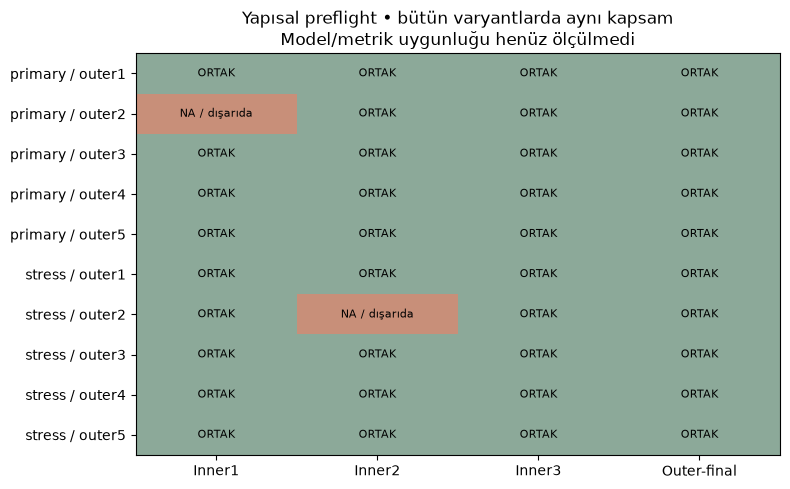

In [4]:
display(pd.read_csv(QA/'failure_policy_options.csv'))
display(scope)
matrix=[];labels=[]
for row in scope.itertuples():
    valid={int(x) for x in row.common_valid_inner_folds.split(',') if x}
    matrix.append([int(i in valid) for i in (1,2,3)]+[int(row.outer_all_three_nulls_valid)])
    labels.append(f'{row.protocol} / outer{row.outer_fold}')
from matplotlib.colors import ListedColormap
fig,ax=plt.subplots(figsize=(8,5));ax.imshow(matrix,aspect='auto',vmin=0,vmax=1,cmap=ListedColormap(['#c88f79','#8ca999']))
ax.set_xticks(range(4),['Inner1','Inner2','Inner3','Outer-final']);ax.set_yticks(range(10),labels)
for i,row in enumerate(matrix):
    for j,value in enumerate(row):ax.text(j,i,'ORTAK' if value else 'NA / dışarıda',ha='center',va='center',fontsize=8)
ax.set_title('Yapısal preflight • bütün varyantlarda aynı kapsam\nModel/metrik uygunluğu henüz ölçülmedi')
plt.tight_layout();plt.savefig(FIG/'03_common_scope.png',dpi=160);plt.show()

**Yorum:** Primary outer2:inner2/3;stress outer2:inner1/3;diğer8 outer:inner1/2/3. Minimum2 ile10/10 outer topolojik olarak hazırdır. Bu durum model/metrik başarısı değildir. Minimum3 seçilse iki outer primary kıyas NA olacaktı. Model başına farklı foldlarla seçim yapmak karşılaştırılabilirliği bozar. Herhangi fit/metrik NA'sında yine bütün5 fit için ortak tanımlı kesişim alınır;düşük AP dışlama nedeni değildir. Kesişim<2 olursa bütün outer primary NA;outer-final null eksikse yine bütün triad NA. Mevcut frozen split/ID/sözlük değişmez;final fit yine aynı outer train'i kullanır.

## 4. Tek konfigürasyon ve doğru mimari adı

,alan,nihai_önerilen_değer,sınır
0,Durum / tek öneri,WP09-training-PROPOSED-v3; training_enabled=False,Ayrı kullanıcı eğitim onayı bekler
1,Birincil PPI eşiği,700; onaylı değer henüz None,Topoloji/null fizibilitesi önerisi; predictive sonuç seçimi değil
2,Diğer eşikler,400/900 ilk primary eğitim isteğinin dışında ertelendi,Eski girdileri/senaryoları silinmedi
3,Mimari,"Protein56→32,tek residual mean PPI;kimya5→8;4 ayrı rol mean+maskeler",Head hariç3920;temsil141;lineer head142×K;atom–bağ GNN yok
4,Varyantlar,"G_noPPI,G_realPPI,G_shuffledPPI×3 sabit null",Aynı yapı/başlangıç parametreleri/context ID/PT/girdi kapsamı
5,Kohort / uygunluk,62 envanter;frozen B2 input-eligible61,Methenamine abstention;Tobramycin kimya;QC kararları aynı
6,Protein evreni,Yalnız train-linked doğrulanmış dizi;aynı-taxID insan induced PPI,K12 koşullu23 kenar/context80 yok;komşusuz dizi self yolunda
7,Hedef / scaler,Mevcut train B2 sözlüğü+ortak train-fittable maskesi;5pozitif/2grup ilkesi,Kaynak1061 PT yeniden seçilmez;dönüşümler mevcut train-only kaynaklardan
8,Loss,"BCEWithLogitsLoss;valid PT ortalaması/eligible drug,sonra drug ortalaması",Unknown0 yalnız kayıt proxy;class_weight/pos_weight yok;single-proxy train PT NA
9,Optimizer / learning rate,AdamW;lr0.001;weight_decay0.001,Kurulmadı/çalıştırılmadı;grid araması yok


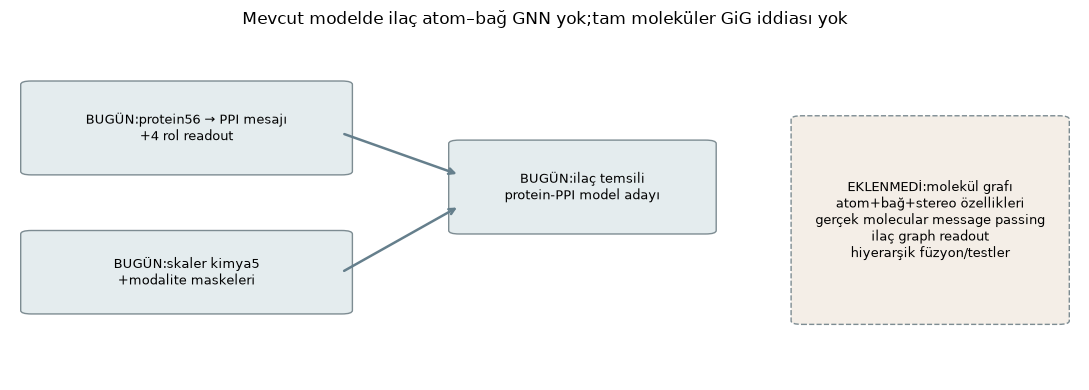

In [5]:
display(pd.read_csv(QA/'final_configuration_table.csv'))
fig,ax=plt.subplots(figsize=(11,4));ax.axis('off')
from matplotlib.patches import FancyBboxPatch
boxes=[(.02,.60,.29,.25,'BUGÜN:protein56 → PPI mesajı\n+4 rol readout'),(.02,.20,.29,.22,'BUGÜN:skaler kimya5\n+modalite maskeleri'),
    (.42,.43,.23,.25,'BUGÜN:ilaç temsili\nprotein-PPI model adayı'),(.74,.17,.24,.58,'EKLENMEDİ:molekül grafı\natom+bağ+stereo özellikleri\ngerçek molecular message passing\nilaç graph readout\nhiyerarşik füzyon/testler')]
for x,y,w,h,label in boxes:
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=.01',facecolor='#e4ecee' if x<.7 else '#f4eee7',edgecolor='#7d8c92',linestyle='--' if x>.7 else '-'))
    ax.text(x+w/2,y+h/2,label,ha='center',va='center',fontsize=9)
for start,end in [((.31,.71),(.42,.59)),((.31,.31),(.42,.50))]:ax.annotate('',xy=end,xytext=start,arrowprops=dict(arrowstyle='->',color='#657f8c',lw=1.8))
ax.set_title('Mevcut modelde ilaç atom–bağ GNN yok;tam moleküler GiG iddiası yok')
plt.tight_layout();plt.savefig(FIG/'04_architecture_scope.png',dpi=160);plt.show()

**Yorum:** Güncel model protein-PPI mesaj geçişli,rol readout ve skaler kimya dallıdır. Tam moleküler GiG için QC-doğrulanmış ilaç atom/bağ grafları,moleküler encoder/readout ve protein katmanıyla hiyerarşik füzyon gerekir;ilgili forward/gradient/ablation ve split kontrolleri ayrı uygulanır. Bunlar WP10 ve sonraki onaylı işlere aittir;bugün yapılmadı. Tablo gelecekteki AdamW/BCE/epoch ayarlarını önerir,hiçbiri çalıştırılmaz. Null generator/bütçe aynıdır;v3 yalnız tekrar,karşılaştırılabilirlik ve NA politikasını tamamlar.

## 5. Uygulanacak eğitim sırası — yalnız önizleme

In [6]:
schedule=pd.read_csv(QA/'training_sequence_PREVIEW_ONLY.csv')
display(schedule.groupby(['phase','variant']).size().rename('gelecekteki_koşullu_fit_sayısı').reset_index())
display(schedule.head(10))
sources=json.loads((QA/'training_preview_sources.json').read_text(encoding='utf-8'))
context='primary_o01_i01';src=sources[context]
display(pd.DataFrame([{'context':context,'graph_train_ids':src['graph_train_ids'],'fit_eligible_train_ids':src['fit_eligible_train_ids'],
    'validation_query_ids':src['validation_query_ids'],'test_query_ids':src['test_query_ids'],
    'declared_train_PT':len(src['declared_train_B2_PT']),'fittable_train_PT':len(src['fittable_train_B2_PT'])}]))

,phase,variant,gelecekteki_koşullu_fit_sayısı
0,INNER_EARLY_STOP,G_noPPI,28
1,INNER_EARLY_STOP,G_realPPI,28
2,INNER_EARLY_STOP,G_shuffledPPI,84
3,OUTER_FINAL_CONDITIONAL_ON_INNER,G_noPPI,10
4,OUTER_FINAL_CONDITIONAL_ON_INNER,G_realPPI,10
5,OUTER_FINAL_CONDITIONAL_ON_INNER,G_shuffledPPI,30


,context,protocol,outer_fold,inner_fold,phase,variant,null_replicate,null_file,init_seed,train_fit_count,identity_and_target_scope_sha256,training_graph_file,query_file,status
0,primary_o01_i01,primary,1,1,INNER_EARLY_STOP,G_noPPI,-1,NaN,20261207,32,e5ccf98a31f119295bdd55aacf5480681433bf792845d217153479c1d43720e3,reports/qa/WP09/design_v1/folds/primary_o01_i01_train.npz,reports/qa/WP09/design_v1/folds/primary_o01_i01_query.npz,NOT_RUN_AWAITING_USER_APPROVAL
1,primary_o01_i01,primary,1,1,INNER_EARLY_STOP,G_realPPI,-1,NaN,20261207,32,e5ccf98a31f119295bdd55aacf5480681433bf792845d217153479c1d43720e3,reports/qa/WP09/design_v1/folds/primary_o01_i01_train.npz,reports/qa/WP09/design_v1/folds/primary_o01_i01_query.npz,NOT_RUN_AWAITING_USER_APPROVAL
2,primary_o01_i01,primary,1,1,INNER_EARLY_STOP,G_shuffledPPI,0,reports/qa/WP09/null_gate_v3/nulls/primary_o01_i01_r0.npz,20261207,32,e5ccf98a31f119295bdd55aacf5480681433bf792845d217153479c1d43720e3,reports/qa/WP09/design_v1/folds/primary_o01_i01_train.npz,reports/qa/WP09/design_v1/folds/primary_o01_i01_query.npz,NOT_RUN_AWAITING_USER_APPROVAL
3,primary_o01_i01,primary,1,1,INNER_EARLY_STOP,G_shuffledPPI,1,reports/qa/WP09/null_gate_v3/nulls/primary_o01_i01_r1.npz,20261207,32,e5ccf98a31f119295bdd55aacf5480681433bf792845d217153479c1d43720e3,reports/qa/WP09/design_v1/folds/primary_o01_i01_train.npz,reports/qa/WP09/design_v1/folds/primary_o01_i01_query.npz,NOT_RUN_AWAITING_USER_APPROVAL
4,primary_o01_i01,primary,1,1,INNER_EARLY_STOP,G_shuffledPPI,2,reports/qa/WP09/null_gate_v3/nulls/primary_o01_i01_r2.npz,20261207,32,e5ccf98a31f119295bdd55aacf5480681433bf792845d217153479c1d43720e3,reports/qa/WP09/design_v1/folds/primary_o01_i01_train.npz,reports/qa/WP09/design_v1/folds/primary_o01_i01_query.npz,NOT_RUN_AWAITING_USER_APPROVAL
5,primary_o01_i02,primary,1,2,INNER_EARLY_STOP,G_noPPI,-1,NaN,20261208,32,8a2d493f0bce26aee311dc8011d9b080f11d1528e0aee484890360849f942a4e,reports/qa/WP09/design_v1/folds/primary_o01_i02_train.npz,reports/qa/WP09/design_v1/folds/primary_o01_i02_query.npz,NOT_RUN_AWAITING_USER_APPROVAL
6,primary_o01_i02,primary,1,2,INNER_EARLY_STOP,G_realPPI,-1,NaN,20261208,32,8a2d493f0bce26aee311dc8011d9b080f11d1528e0aee484890360849f942a4e,reports/qa/WP09/design_v1/folds/primary_o01_i02_train.npz,reports/qa/WP09/design_v1/folds/primary_o01_i02_query.npz,NOT_RUN_AWAITING_USER_APPROVAL
7,primary_o01_i02,primary,1,2,INNER_EARLY_STOP,G_shuffledPPI,0,reports/qa/WP09/null_gate_v3/nulls/primary_o01_i02_r0.npz,20261208,32,8a2d493f0bce26aee311dc8011d9b080f11d1528e0aee484890360849f942a4e,reports/qa/WP09/design_v1/folds/primary_o01_i02_train.npz,reports/qa/WP09/design_v1/folds/primary_o01_i02_query.npz,NOT_RUN_AWAITING_USER_APPROVAL
8,primary_o01_i02,primary,1,2,INNER_EARLY_STOP,G_shuffledPPI,1,reports/qa/WP09/null_gate_v3/nulls/primary_o01_i02_r1.npz,20261208,32,8a2d493f0bce26aee311dc8011d9b080f11d1528e0aee484890360849f942a4e,reports/qa/WP09/design_v1/folds/primary_o01_i02_train.npz,reports/qa/WP09/design_v1/folds/primary_o01_i02_query.npz,NOT_RUN_AWAITING_USER_APPROVAL
9,primary_o01_i02,primary,1,2,INNER_EARLY_STOP,G_shuffledPPI,2,reports/qa/WP09/null_gate_v3/nulls/primary_o01_i02_r2.npz,20261208,32,8a2d493f0bce26aee311dc8011d9b080f11d1528e0aee484890360849f942a4e,reports/qa/WP09/design_v1/folds/primary_o01_i02_train.npz,reports/qa/WP09/design_v1/folds/primary_o01_i02_query.npz,NOT_RUN_AWAITING_USER_APPROVAL


,context,graph_train_ids,fit_eligible_train_ids,validation_query_ids,test_query_ids,declared_train_PT,fittable_train_PT
0,primary_o01_i01,"[DB00199, DB00207, DB00259, DB00301, DB00303, DB00319, DB00359, DB00415, DB00440, DB00485, DB00512, DB00560, DB00567...","[DB00199, DB00207, DB00259, DB00301, DB00303, DB00319, DB00359, DB00415, DB00440, DB00485, DB00512, DB00560, DB00567...","[DB00417, DB00535, DB00595, DB00601, DB00779, DB00798, DB00916, DB01044, DB01059, DB01060, DB01211, DB01331, DB01413...","[DB00254, DB00438, DB00446, DB00479, DB00493, DB00537, DB00685, DB01137, DB01155, DB01165, DB01208, DB01332, DB06590]",171,171


**Yorum:** 190 koşullu plan işi:140 inner,50 outer-final. Çalıştırılan fit sayısı0'dır. Her contextte real/noPPI ve3 shuffled aynı ID/hedef/hash/init ile planlanır. Önce kullanıcı onayı+hash doğrulama,sonra ortak inner fit/early-stop;en az2 geçerli inner epoch medyanıyla outer refit;en son aynı query kapsamı/paired karşılaştırma. PT hedef listeleri burada yalnız önceki kilitli train metadata'sıdır;null tanısına etiket matrisi veya performans girmez. Shuffled3 metriğinin eşit ortalaması özetlenir;PT skorları ensemble yapılmaz ve en iyi replica seçilmez. Gerçek sonuçlar alındıktan sonra yeni hyperparameter araması yoktur.

## 6. Test ve koruma

In [7]:
text=(QA/'test_results.txt').read_text(encoding='utf-8');test=re.search(r'Ran ([0-9]+) tests in ([0-9.]+)s',text)
display(pd.DataFrame([{'null_kapısı_testi':int(test.group(1)),'saniye':float(test.group(2)),'tümü_geçti':text.rstrip().endswith('OK'),
    'korunan_önceki_dosya':done['prior_files_verified'],'gerçek_model_fit':False,'optimizer':False,'PT_skoru':False,
    'eski_B0_B1_B2_değişti':False,'eğitim_onayı':c['training_enabled']}]))
display(pd.DataFrame([{'gelecek_eğitim_araştırma_sorusu':'SIDER observed-record sıralaması','unknown':'gerçek negatif değil',
    'klinik_risk_iddiası':False,'gelecek_kıyas':'WP08 sonuçları görülmüş olduğundan keşifsel'}]))

,null_kapısı_testi,saniye,tümü_geçti,korunan_önceki_dosya,gerçek_model_fit,optimizer,PT_skoru,eski_B0_B1_B2_değişti,eğitim_onayı
0,18,3.839,True,1567,False,False,False,False,False


,gelecek_eğitim_araştırma_sorusu,unknown,klinik_risk_iddiası,gelecek_kıyas
0,SIDER observed-record sıralaması,gerçek negatif değil,False,WP08 sonuçları görülmüş olduğundan keşifsel


**Yorum:**18 test eski40 R0 endpoint'ini,seed/hash ve null derece/count basitgraf kısıtlarını,3 NA'nın dosya eksikliğini,ortak-fold/minimum2/outer-NA kusur enjeksiyonlarını ve aynı ID/PT/init planını doğrular. Önceki35 encoder testi korunur;bu ek yeniden encoder doğrulaması yapmış sayılmaz.62 ilaç,1061 PT ve6416 kaynak pozitif ilişkisi hash'le korundu;etiketler yeniden analiz edilmedi.

Kaynaklar yalnız yöntem içindir: [NetworkX double-edge-swap](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.swap.double_edge_swap.html),[Fosdick ve ark.](https://arxiv.org/abs/1608.00607),[Dutta ve ark.](https://arxiv.org/abs/2105.12120). Derece korumak uniform mixing kanıtı değildir;sonlu null tekrarı bağımsız dış doğrulama değildir.

[Tek nihai eğitim kapısı](../reports/WP09_FINAL_TRAINING_GATE.md) gerekçeyi ve sıralamayı içerir. **Model fit edilmedi;ayrı kullanıcı eğitim onayı bekleniyor.**